<a href="https://colab.research.google.com/github/jaiborojas-cloud/leviathan/blob/main/Perspectivas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
"""
EXPERIMENTO 1
=============

Objetivos:

1. Implementar manualmente una red neuronal pequeña.
2. Realizar el forward pass.
3. Calcular Binary Cross Entropy.
4. Implementar backpropagation manual.
5. Validar los gradientes mediante diferencias finitas.
6. Comparar posteriormente con PyTorch/autograd.
7. Reparametrizar la red manteniendo la misma función.
8. Observar cómo cambian los gradientes paramétricos.
9. Comprobar la transformación covectorial mediante la regla de la cadena.

Arquitectura:

x -> Linear(1,2) -> ReLU
  -> Linear(2,3) -> ReLU
  -> Linear(3,1) -> Sigmoid


Experimento 1 — Parametric Equivalence and Euclidean Gradient Divergence (PEGD)
Equivalencia paramétrica y divergencia del gradiente euclídeo.

Objetivo: demostrar que dos parametrizaciones que representan la misma función pueden producir trayectorias distintas bajo gradient descent euclídeo.
"""

In [ ]:
import numpy as np
import pandas as pd

np.set_printoptions(
    precision=10,
    suppress=True
)

print("NumPy:", np.__version__)

In [ ]:
# Entrada
x = np.array([[0.8]])

# Etiqueta verdadera
y = np.array([[1.0]])


# -----------------------
# CAPA 1
# -----------------------

W1 = np.array([
    [ 0.2],
    [-0.2]
])

b1 = np.array([
    [-0.06],
    [ 0.26]
])


# -----------------------
# CAPA 2
# -----------------------

W2 = np.array([
    [ 0.5, -0.5],
    [ 0.5,  0.5],
    [-0.5,  0.5]
])

b2 = np.array([
    [0.05],
    [0.00],
    [0.02]
])


# -----------------------
# CAPA 3
# -----------------------

W3 = np.array([
    [-0.8, 0.8, 0.8]
])

b3 = np.array([
    [0.0]
])


print("x =", x)
print("\nW1 =\n", W1)
print("\nW2 =\n", W2)
print("\nW3 =\n", W3)

In [ ]:
# Entrada
x = np.array([[0.8]])

# Etiqueta verdadera
y = np.array([[1.0]])


# -----------------------
# CAPA 1
# -----------------------

W1 = np.array([
    [ 0.2],
    [-0.2]
])

b1 = np.array([
    [-0.06],
    [ 0.26]
])


# -----------------------
# CAPA 2
# -----------------------

W2 = np.array([
    [ 0.5, -0.5],
    [ 0.5,  0.5],
    [-0.5,  0.5]
])

b2 = np.array([
    [0.05],
    [0.00],
    [0.02]
])


# -----------------------
# CAPA 3
# -----------------------

W3 = np.array([
    [-0.8, 0.8, 0.8]
])

b3 = np.array([
    [0.0]
])


print("x =", x)
print("\nW1 =\n", W1)
print("\nW2 =\n", W2)
print("\nW3 =\n", W3)

In [ ]:
def relu(z):
    return np.maximum(0.0, z)


def relu_derivative(z):
    return (z > 0).astype(float)


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


def binary_cross_entropy(y_true, y_pred):
    eps = 1e-12

    y_pred = np.clip(
        y_pred,
        eps,
        1.0 - eps
    )

    return -np.mean(
        y_true * np.log(y_pred)
        +
        (1.0 - y_true) * np.log(1.0 - y_pred)
    )

In [ ]:
def forward(x, W1, b1, W2, b2, W3, b3):

    # Primera capa
    z1 = W1 @ x + b1
    h1 = relu(z1)

    # Segunda capa
    z2 = W2 @ h1 + b2
    h2 = relu(z2)

    # Salida
    o = W3 @ h2 + b3
    y_pred = sigmoid(o)

    return {
        "z1": z1,
        "h1": h1,
        "z2": z2,
        "h2": h2,
        "o": o,
        "y_pred": y_pred
    }


cache = forward(
    x,
    W1, b1,
    W2, b2,
    W3, b3
)

for name, value in cache.items():
    print(f"\n{name}:")
    print(value)

In [ ]:
loss = binary_cross_entropy(
    y,
    cache["y_pred"]
)

print("Predicción :", cache["y_pred"].item())
print("Target     :", y.item())
print("Loss       :", loss)

In [ ]:
def backward(x, y, cache, W1, W2, W3):

    z1 = cache["z1"]
    h1 = cache["h1"]

    z2 = cache["z2"]
    h2 = cache["h2"]

    y_pred = cache["y_pred"]


    # --------------------------------
    # SALIDA
    # --------------------------------

    do = y_pred - y


    # --------------------------------
    # W3
    # --------------------------------

    dW3 = do @ h2.T
    db3 = do


    # --------------------------------
    # CAPA 2
    # --------------------------------

    dh2 = W3.T @ do

    dz2 = dh2 * relu_derivative(z2)

    dW2 = dz2 @ h1.T
    db2 = dz2


    # --------------------------------
    # CAPA 1
    # --------------------------------

    dh1 = W2.T @ dz2

    dz1 = dh1 * relu_derivative(z1)

    dW1 = dz1 @ x.T
    db1 = dz1


    return {
        "W1": dW1,
        "b1": db1,
        "W2": dW2,
        "b2": db2,
        "W3": dW3,
        "b3": db3
    }


grads = backward(
    x,
    y,
    cache,
    W1,
    W2,
    W3
)

for name, value in grads.items():
    print(f"\ndL/d{name}:")
    print(value)

In [ ]:
def compute_loss(x, y, W1, b1, W2, b2, W3, b3):

    result = forward(
        x,
        W1, b1,
        W2, b2,
        W3, b3
    )

    return binary_cross_entropy(
        y,
        result["y_pred"]
    )

In [ ]:
epsilon = 1e-5


W1_plus = W1.copy()
W1_minus = W1.copy()

W1_plus[0,0] += epsilon
W1_minus[0,0] -= epsilon


loss_plus = compute_loss(
    x, y,
    W1_plus, b1,
    W2, b2,
    W3, b3
)

loss_minus = compute_loss(
    x, y,
    W1_minus, b1,
    W2, b2,
    W3, b3
)


numeric_gradient = (
    loss_plus - loss_minus
) / (2 * epsilon)


analytic_gradient = grads["W1"][0,0]


print("Backpropagation :", analytic_gradient)
print("Finite difference:", numeric_gradient)
print("Difference       :", abs(
    analytic_gradient - numeric_gradient
))

In [ ]:
def numerical_gradient(
    parameter_name,
    parameters,
    x,
    y,
    epsilon=1e-5
):

    parameter = parameters[parameter_name]

    numerical = np.zeros_like(parameter)


    for index in np.ndindex(parameter.shape):

        plus_params = {
            k: v.copy()
            for k, v in parameters.items()
        }

        minus_params = {
            k: v.copy()
            for k, v in parameters.items()
        }


        plus_params[parameter_name][index] += epsilon
        minus_params[parameter_name][index] -= epsilon


        loss_plus = compute_loss(
            x, y,
            plus_params["W1"],
            plus_params["b1"],
            plus_params["W2"],
            plus_params["b2"],
            plus_params["W3"],
            plus_params["b3"]
        )


        loss_minus = compute_loss(
            x, y,
            minus_params["W1"],
            minus_params["b1"],
            minus_params["W2"],
            minus_params["b2"],
            minus_params["W3"],
            minus_params["b3"]
        )


        numerical[index] = (
            loss_plus - loss_minus
        ) / (2 * epsilon)


    return numerical

In [ ]:
parameters = {
    "W1": W1,
    "b1": b1,
    "W2": W2,
    "b2": b2,
    "W3": W3,
    "b3": b3
}


rows = []


for name in parameters:

    numeric = numerical_gradient(
        name,
        parameters,
        x,
        y
    )

    analytic = grads[name]


    for index in np.ndindex(analytic.shape):

        a = analytic[index]
        n = numeric[index]

        relative_error = (
            abs(a - n)
            /
            max(1.0, abs(a), abs(n))
        )

        rows.append({
            "parameter": name,
            "index": str(index),
            "backprop": a,
            "finite_difference": n,
            "relative_error": relative_error
        })


gradient_check = pd.DataFrame(rows)

gradient_check

In [ ]:
tolerance = 1e-6

gradient_check["status"] = np.where(
    gradient_check["relative_error"] < tolerance,
    "PASS",
    "FAIL"
)

gradient_check

print(
    "Maximum relative error:",
    gradient_check["relative_error"].max()
)

print()

if (gradient_check["status"] == "PASS").all():
    print("✓ TODOS LOS GRADIENTES SON CORRECTOS")
else:
    print("✗ EXISTEN GRADIENTES INCORRECTOS")

In [ ]:
c = 5.0


W1_prime = c * W1
b1_prime = c * b1

W2_prime = W2 / c


# Lo demás permanece idéntico

b2_prime = b2.copy()
W3_prime = W3.copy()
b3_prime = b3.copy()

print("W1 original:")
print(W1)

print("\nW1 reparametrizado:")
print(W1_prime)

print("\nW2 original:")
print(W2)

print("\nW2 reparametrizado:")
print(W2_prime)

In [ ]:
original = forward(
    x,
    W1, b1,
    W2, b2,
    W3, b3
)


reparameterized = forward(
    x,
    W1_prime, b1_prime,
    W2_prime, b2_prime,
    W3_prime, b3_prime
)


print(
    "Original prediction:",
    original["y_pred"].item()
)

print(
    "Reparameterized prediction:",
    reparameterized["y_pred"].item()
)

print(
    "Difference:",
    abs(
        original["y_pred"].item()
        -
        reparameterized["y_pred"].item()
    )
)

In [ ]:
loss_original = binary_cross_entropy(
    y,
    original["y_pred"]
)


loss_prime = binary_cross_entropy(
    y,
    reparameterized["y_pred"]
)


print("Original loss       :", loss_original)
print("Reparameterized loss:", loss_prime)
print("Difference          :", abs(loss_original-loss_prime))

In [ ]:
grads_original = backward(
    x,
    y,
    original,
    W1,
    W2,
    W3
)


grads_prime = backward(
    x,
    y,
    reparameterized,
    W1_prime,
    W2_prime,
    W3_prime
)

print("Gradient W1 original:")
print(grads_original["W1"])

print("\nGradient W1 reparameterized:")
print(grads_prime["W1"])

print("\nGradient W2 original:")
print(grads_original["W2"])

print("\nGradient W2 reparameterized:")
print(grads_prime["W2"])


print("Norm W1 gradient original:")
print(np.linalg.norm(grads_original["W1"]))

print("\nNorm W1 gradient transformed:")
print(np.linalg.norm(grads_prime["W1"]))


print("\nNorm W2 gradient original:")
print(np.linalg.norm(grads_original["W2"]))

print("\nNorm W2 gradient transformed:")
print(np.linalg.norm(grads_prime["W2"]))

In [ ]:
comparison = pd.DataFrame({

    "quantity": [
        "prediction",
        "loss",
        "||grad W1||",
        "||grad W2||"
    ],

    "original": [
        original["y_pred"].item(),
        loss_original,
        np.linalg.norm(grads_original["W1"]),
        np.linalg.norm(grads_original["W2"])
    ],

    "reparameterized": [
        reparameterized["y_pred"].item(),
        loss_prime,
        np.linalg.norm(grads_prime["W1"]),
        np.linalg.norm(grads_prime["W2"])
    ]
})

comparison

In [ ]:
predicted_dW1_prime = (
    grads_original["W1"] / c
)

predicted_dW2_prime = (
    grads_original["W2"] * c
)


print("dW1' obtenido por backprop:")
print(grads_prime["W1"])

print("\ndW1' predicho por transformación:")
print(predicted_dW1_prime)


print("\n-----------------------------\n")


print("dW2' obtenido por backprop:")
print(grads_prime["W2"])

print("\ndW2' predicho por transformación:")
print(predicted_dW2_prime)

In [ ]:
error_W1 = np.max(
    np.abs(
        grads_prime["W1"]
        -
        predicted_dW1_prime
    )
)


error_W2 = np.max(
    np.abs(
        grads_prime["W2"]
        -
        predicted_dW2_prime
    )
)


print("Covector transformation error W1:", error_W1)
print("Covector transformation error W2:", error_W2)

In [ ]:
tolerance = 1e-10


same_function = np.allclose(
    original["y_pred"],
    reparameterized["y_pred"],
    atol=tolerance
)


covector_W1_correct = np.allclose(
    grads_prime["W1"],
    grads_original["W1"] / c,
    atol=tolerance
)


covector_W2_correct = np.allclose(
    grads_prime["W2"],
    grads_original["W2"] * c,
    atol=tolerance
)


print("Same represented function:", same_function)
print("W1 covector law          :", covector_W1_correct)
print("W2 covector law          :", covector_W2_correct)

In [ ]:
import torch

torch.set_default_dtype(torch.float64)

xt = torch.tensor([[0.8]], requires_grad=False)
yt = torch.tensor([[1.0]])

# (Assuming W1, b1, etc. are already defined NumPy arrays or lists)
W1t = torch.tensor(W1, requires_grad=True)
b1t = torch.tensor(b1, requires_grad=True)
W2t = torch.tensor(W2, requires_grad=True)
b2t = torch.tensor(b2, requires_grad=True)
W3t = torch.tensor(W3, requires_grad=True)
b3t = torch.tensor(b3, requires_grad=True)

# --- Forward Pass ---
z1t = W1t @ xt + b1t
h1t = torch.relu(z1t)

z2t = W2t @ h1t + b2t
h2t = torch.relu(z2t)

ot = W3t @ h2t + b3t
ypred_t = torch.sigmoid(ot)

# --- Calculate Loss ---
# Using Binary Cross-Entropy Loss formula to match typical manual sigmoid classifications
loss = - (yt * torch.log(ypred_t) + (1.0 - yt) * torch.log(1.0 - ypred_t)).mean()

# --- Backward Pass ---
# This line populates W1t.grad, b1t.grad, etc.
loss.backward()

# --- Print Outputs ---
print("MANUAL:")
print(grads["W1"])

print("\nPYTORCH:")
with torch.no_grad():
    print(W1t.grad.numpy())

print("\nDifference:")
with torch.no_grad():
    print(grads["W1"] - W1t.grad.numpy())


In [ ]:
eta = 0.1

# ----- Paso GD en parametrización original -----
W1_next = W1 - eta * grads_original["W1"]
b1_next = b1 - eta * grads_original["b1"]
W2_next = W2 - eta * grads_original["W2"]
b2_next = b2 - eta * grads_original["b2"]
W3_next = W3 - eta * grads_original["W3"]
b3_next = b3 - eta * grads_original["b3"]

# ----- Paso GD en parametrización reparametrizada -----
W1p_next = W1_prime - eta * grads_prime["W1"]
b1p_next = b1_prime - eta * grads_prime["b1"]
W2p_next = W2_prime - eta * grads_prime["W2"]
b2p_next = b2_prime - eta * grads_prime["b2"]
W3p_next = W3_prime - eta * grads_prime["W3"]
b3p_next = b3_prime - eta * grads_prime["b3"]

In [ ]:
after_original = forward(
    x,
    W1_next, b1_next,
    W2_next, b2_next,
    W3_next, b3_next
)

after_prime = forward(
    x,
    W1p_next, b1p_next,
    W2p_next, b2p_next,
    W3p_next, b3p_next
)

print("Prediction after GD - original:")
print(after_original["y_pred"].item())

print("\nPrediction after GD - reparameterized:")
print(after_prime["y_pred"].item())

print("\nDifference:")
print(abs(
    after_original["y_pred"].item()
    -
    after_prime["y_pred"].item()
))

In [ ]:
loss_after_original = binary_cross_entropy(
    y,
    after_original["y_pred"]
)

loss_after_prime = binary_cross_entropy(
    y,
    after_prime["y_pred"]
)

print("Loss after GD - original       :", loss_after_original)
print("Loss after GD - reparameterized:", loss_after_prime)
print("Loss difference                :", abs(loss_after_original-loss_after_prime))

In [ ]:
"""
EXPERIMENTO 2 — MCUI
Metric-Covariant Update Invariance

Objetivo:

Comprobar que un vector de actualización construido a partir de una
métrica que se transforma covariantemente representa el mismo vector
geométrico bajo dos parametrizaciones diferentes.

Queremos verificar:

    dL' = J^{-T} dL

    g' = J^{-T} g J^{-1}

    v  = -g^{-1} dL

    v' = -(g')^{-1} dL'

y finalmente:

    v' = J v
"""

In [ ]:
def flatten_parameters(W1, W2):
    return np.concatenate([
        W1.flatten(),
        W2.flatten()
    ])


theta = flatten_parameters(
    W1,
    W2
)

theta_prime = flatten_parameters(
    W1_prime,
    W2_prime
)


print("theta:")
print(theta)

print("\ntheta prime:")
print(theta_prime)

print("\nDimension:", theta.shape[0])

In [ ]:
def flatten_gradients(dW1, dW2):
    return np.concatenate([
        dW1.flatten(),
        dW2.flatten()
    ])


dL = flatten_gradients(
    grads_original["W1"],
    grads_original["W2"]
)


dL_prime = flatten_gradients(
    grads_prime["W1"],
    grads_prime["W2"]
)


print("dL:")
print(dL)

print("\ndL prime:")
print(dL_prime)

In [ ]:
n_W1 = W1.size
n_W2 = W2.size

J = np.zeros((
    n_W1 + n_W2,
    n_W1 + n_W2
))


# W1
J[:n_W1, :n_W1] = (
    c * np.eye(n_W1)
)


# W2
J[n_W1:, n_W1:] = (
    (1.0 / c) * np.eye(n_W2)
)


print("Jacobian J:")
print(J)

In [ ]:
theta_prime_predicted = J @ theta


print("theta prime real:")
print(theta_prime)

print("\ntheta prime predicted:")
print(theta_prime_predicted)

print(
    "\nError:",
    np.linalg.norm(
        theta_prime -
        theta_prime_predicted
    )
)

In [ ]:
J_inv = np.linalg.inv(J)

dL_prime_predicted = (
    J_inv.T @ dL
)


print("dL prime from backprop:")
print(dL_prime)

print("\ndL prime predicted:")
print(dL_prime_predicted)

print(
    "\nError:",
    np.linalg.norm(
        dL_prime -
        dL_prime_predicted
    )
)

In [ ]:
dimension = theta.shape[0]

g = np.eye(dimension)

print("Metric g:")
print(g)

In [ ]:
g_prime = (
    J_inv.T
    @ g
    @ J_inv
)


print("Transformed metric g':")
print(g_prime)

In [ ]:
print(
    "Is g prime identity?",
    np.allclose(
        g_prime,
        np.eye(dimension)
    )
)

In [ ]:
g_inv = np.linalg.inv(g)


v = -g_inv @ dL


print("Update vector v:")
print(v)

In [ ]:
g_prime_inv = np.linalg.inv(
    g_prime
)


v_prime = (
    -g_prime_inv
    @ dL_prime
)


print("Update vector v prime:")
print(v_prime)

In [ ]:
v_prime_predicted = J @ v


print("v prime calculated:")
print(v_prime)

print("\nv prime predicted by Jv:")
print(v_prime_predicted)

print(
    "\nError:",
    np.linalg.norm(
        v_prime -
        v_prime_predicted
    )
)

In [ ]:
metric_covariance_error = np.linalg.norm(
    v_prime -
    J @ v
)


tolerance = 1e-10


if metric_covariance_error < tolerance:

    print(
        "✓ MCUI PASS — "
        "Metric-covariant update is invariant"
    )

else:

    print(
        "✗ MCUI FAIL"
    )


print(
    "Error:",
    metric_covariance_error
)

In [ ]:
v_euclidean = -dL

v_euclidean_prime = -dL_prime


euclidean_error = np.linalg.norm(
    v_euclidean_prime
    -
    J @ v_euclidean
)


metric_error = np.linalg.norm(
    v_prime
    -
    J @ v
)


print(
    "Euclidean coordinate error:",
    euclidean_error
)

print(
    "Metric-covariant error:",
    metric_error
)

In [ ]:
results = pd.DataFrame({

    "experiment": [
        "PEGD",
        "MCUI"
    ],

    "update_rule": [
        "-dL with identity metric in both charts",
        "-g^{-1} dL with transformed metric"
    ],

    "invariance_error": [
        euclidean_error,
        metric_error
    ],

    "invariant": [
        euclidean_error < 1e-10,
        metric_error < 1e-10
    ]
})


results

In [ ]:
"""
EXPERIMENTO 3 — FTI
Functional Trajectory Invariance

Objetivo:

Comparar dos dinámicas de optimización iniciadas desde
parametrizaciones funcionalmente equivalentes.

A) Euclidean Gradient Descent
   theta_{t+1} = theta_t - eta dL_t

B) Metric-Covariant Gradient Flow discretizado
   theta_{t+1} = theta_t - eta g^{-1} dL_t

Comprobaremos si dos cartas relacionadas por:

    theta' = J theta

mantienen:

    F_theta_t(x) = F_theta'_t(x)

a lo largo de múltiples pasos.

Como la transformación usada aquí es lineal y J es constante,
la actualización discreta también debería respetar exactamente
la transformación en el caso métrico, salvo error numérico.
"""

In [ ]:
def pack_params(W1, b1, W2, b2, W3, b3):
    return np.concatenate([
        W1.ravel(),
        b1.ravel(),
        W2.ravel(),
        b2.ravel(),
        W3.ravel(),
        b3.ravel()
    ])

shapes = {
    "W1": W1.shape,
    "b1": b1.shape,
    "W2": W2.shape,
    "b2": b2.shape,
    "W3": W3.shape,
    "b3": b3.shape
}


sizes = {
    name: np.prod(shape)
    for name, shape in shapes.items()
}


def unpack_params(theta):

    cursor = 0
    params = {}

    for name in ["W1", "b1", "W2", "b2", "W3", "b3"]:

        size = sizes[name]

        params[name] = theta[
            cursor:cursor + size
        ].reshape(shapes[name])

        cursor += size

    return params

theta0 = pack_params(
    W1, b1,
    W2, b2,
    W3, b3
)

recovered = unpack_params(theta0)

print("Total parameters:", len(theta0))

for name, value in recovered.items():
    print(f"\n{name}:")
    print(value)

In [ ]:
def pack_grads(grads):
    return np.concatenate([
        grads["W1"].ravel(),
        grads["b1"].ravel(),
        grads["W2"].ravel(),
        grads["b2"].ravel(),
        grads["W3"].ravel(),
        grads["b3"].ravel()
    ])

In [ ]:
def forward_theta(theta, x):

    p = unpack_params(theta)

    return forward(
        x,
        p["W1"],
        p["b1"],
        p["W2"],
        p["b2"],
        p["W3"],
        p["b3"]
    )

def loss_and_gradient(theta, x, y):

    p = unpack_params(theta)

    cache = forward(
        x,
        p["W1"],
        p["b1"],
        p["W2"],
        p["b2"],
        p["W3"],
        p["b3"]
    )

    loss = binary_cross_entropy(
        y,
        cache["y_pred"]
    )

    grads = backward(
        x,
        y,
        cache,
        p["W1"],
        p["W2"],
        p["W3"]
    )

    dL = pack_grads(grads)

    return loss, dL

In [ ]:
scale_factors = []

scale_factors += [c] * sizes["W1"]
scale_factors += [c] * sizes["b1"]

scale_factors += [1.0 / c] * sizes["W2"]

scale_factors += [1.0] * sizes["b2"]
scale_factors += [1.0] * sizes["W3"]
scale_factors += [1.0] * sizes["b3"]


J_full = np.diag(scale_factors)

J_full_inv = np.linalg.inv(J_full)


print("J shape:", J_full.shape)
print("Parameter dimension:", len(theta0))

In [ ]:
theta0_prime = J_full @ theta0

original_check = forward_theta(
    theta0,
    x
)["y_pred"]


prime_check = forward_theta(
    theta0_prime,
    x
)["y_pred"]


print("Original:", original_check.item())
print("Prime   :", prime_check.item())

print(
    "Difference:",
    abs(
        original_check.item()
        -
        prime_check.item()
    )
)

In [ ]:
dim = len(theta0)

g = np.eye(dim)

In [ ]:
g_prime = (
    J_full_inv.T
    @ g
    @ J_full_inv
)


g_inv = np.linalg.inv(g)

g_prime_inv = np.linalg.inv(
    g_prime
)

In [ ]:
loss0, dL0 = loss_and_gradient(
    theta0,
    x,
    y
)


loss0_prime, dL0_prime = loss_and_gradient(
    theta0_prime,
    x,
    y
)


predicted_dL0_prime = (
    J_full_inv.T @ dL0
)


print("Loss original:", loss0)
print("Loss prime   :", loss0_prime)

print(
    "\nCovector transformation error:",
    np.linalg.norm(
        dL0_prime
        -
        predicted_dL0_prime
    )
)

In [ ]:
x_grid = np.linspace(
    -4.0,
    4.0,
    401
)

In [ ]:
def evaluate_function(theta, x_values):

    outputs = []

    for value in x_values:

        xi = np.array([
            [value]
        ])

        pred = forward_theta(
            theta,
            xi
        )["y_pred"].item()

        outputs.append(pred)

    return np.array(outputs)

In [ ]:
def functional_distance(
    theta_a,
    theta_b,
    x_values=x_grid
):

    fa = evaluate_function(
        theta_a,
        x_values
    )

    fb = evaluate_function(
        theta_b,
        x_values
    )

    return np.sqrt(
        np.mean(
            (fa - fb)**2
        )
    )

In [ ]:
print(
    "Initial functional distance:",
    functional_distance(
        theta0,
        theta0_prime
    )
)

In [ ]:
def euclidean_step(theta, x, y, eta):

    loss, dL = loss_and_gradient(
        theta,
        x,
        y
    )

    theta_next = (
        theta
        -
        eta * dL
    )

    return theta_next, loss

In [ ]:
def metric_step(
    theta,
    metric_inverse,
    x,
    y,
    eta
):

    loss, dL = loss_and_gradient(
        theta,
        x,
        y
    )

    v = (
        -metric_inverse
        @ dL
    )

    theta_next = (
        theta
        +
        eta * v
    )

    return theta_next, loss

In [ ]:
eta_e3 = 0.02
steps = 50

# Euclidean pair
theta_e = theta0.copy()
theta_e_prime = theta0_prime.copy()


# Metric-covariant pair
theta_m = theta0.copy()
theta_m_prime = theta0_prime.copy()

history = []

In [ ]:
for t in range(steps + 1):

    # ----------------------------------------
    # DISTANCIAS FUNCIONALES
    # ----------------------------------------

    euclidean_distance = functional_distance(
        theta_e,
        theta_e_prime
    )

    metric_distance = functional_distance(
        theta_m,
        theta_m_prime
    )


    # ----------------------------------------
    # RELACIÓN PARAMÉTRICA ESPERADA
    # ----------------------------------------

    euclidean_parameter_error = np.linalg.norm(
        theta_e_prime
        -
        J_full @ theta_e
    )

    metric_parameter_error = np.linalg.norm(
        theta_m_prime
        -
        J_full @ theta_m
    )


    # ----------------------------------------
    # LOSS
    # ----------------------------------------

    loss_e, _ = loss_and_gradient(
        theta_e,
        x,
        y
    )

    loss_ep, _ = loss_and_gradient(
        theta_e_prime,
        x,
        y
    )

    loss_m, _ = loss_and_gradient(
        theta_m,
        x,
        y
    )

    loss_mp, _ = loss_and_gradient(
        theta_m_prime,
        x,
        y
    )


    history.append({
        "step": t,

        "euclidean_function_distance":
            euclidean_distance,

        "metric_function_distance":
            metric_distance,

        "euclidean_parameter_error":
            euclidean_parameter_error,

        "metric_parameter_error":
            metric_parameter_error,

        "loss_e":
            loss_e,

        "loss_e_prime":
            loss_ep,

        "loss_m":
            loss_m,

        "loss_m_prime":
            loss_mp
    })


    # Último paso: solamente registrar
    if t == steps:
        break


    # ========================================
    # EUCLIDEAN GD
    # ========================================

    theta_e, _ = euclidean_step(
        theta_e,
        x,
        y,
        eta_e3
    )

    theta_e_prime, _ = euclidean_step(
        theta_e_prime,
        x,
        y,
        eta_e3
    )


    # ========================================
    # METRIC-COVARIANT
    # ========================================

    theta_m, _ = metric_step(
        theta_m,
        g_inv,
        x,
        y,
        eta_e3
    )

    theta_m_prime, _ = metric_step(
        theta_m_prime,
        g_prime_inv,
        x,
        y,
        eta_e3
    )

In [ ]:
history_df = pd.DataFrame(history)

history_df.head()

history_df.tail()

In [ ]:
print("FINAL RESULTS")
print("=" * 50)

print(
    "Euclidean functional distance:",
    history_df[
        "euclidean_function_distance"
    ].iloc[-1]
)

print(
    "Metric functional distance:",
    history_df[
        "metric_function_distance"
    ].iloc[-1]
)


print()

print(
    "Euclidean parameter relation error:",
    history_df[
        "euclidean_parameter_error"
    ].iloc[-1]
)

print(
    "Metric parameter relation error:",
    history_df[
        "metric_parameter_error"
    ].iloc[-1]
)

In [ ]:
fti_tolerance = 1e-10


metric_final_distance = (
    history_df[
        "metric_function_distance"
    ].iloc[-1]
)


euclidean_final_distance = (
    history_df[
        "euclidean_function_distance"
    ].iloc[-1]
)


print("E3 — FTI")
print("=" * 40)


if (metric_final_distance < fti_tolerance).all():
    print(
        "✓ FTI PASS — "
        "Metric trajectory remained "
        "functionally invariant"
    )
else:
    print(
        "✗ FTI FAIL — "
        "Metric trajectory diverged"
    )


print()

print(
    "Euclidean functional divergence:",
    euclidean_final_distance
)

print(
    "Metric functional divergence:",
    metric_final_distance
)

In [ ]:
import matplotlib.pyplot as plt


plt.figure(figsize=(10, 6))

plt.plot(
    history_df["step"],
    history_df["euclidean_function_distance"],
    label="Euclidean GD"
)

plt.plot(
    history_df["step"],
    history_df["metric_function_distance"],
    label="Metric-covariant"
)

plt.yscale("log")

plt.xlabel("Optimization step")
plt.ylabel("Functional distance (RMSE)")
plt.title(
    "E3 — Functional Trajectory Invariance"
)

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    history_df["step"],
    history_df["loss_e"],
    label="Euclidean — chart θ"
)

plt.plot(
    history_df["step"],
    history_df["loss_e_prime"],
    label="Euclidean — chart θ'"
)

plt.xlabel("Optimization step")
plt.ylabel("Loss")

plt.title(
    "E3 — Euclidean trajectories"
)

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    history_df["step"],
    history_df["loss_m"],
    label="Metric — chart θ"
)

plt.plot(
    history_df["step"],
    history_df["loss_m_prime"],
    label="Metric — chart θ'"
)

plt.xlabel("Optimization step")
plt.ylabel("Loss")

plt.title(
    "E3 — Metric-covariant trajectories"
)

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
summary_e3 = pd.DataFrame({
    "method": [
        "Euclidean GD",
        "Metric-covariant"
    ],

    "initial_function_distance": [
        history_df[
            "euclidean_function_distance"
        ].iloc[0],

        history_df[
            "metric_function_distance"
        ].iloc[0]
    ],

    "final_function_distance": [
        history_df[
            "euclidean_function_distance"
        ].iloc[-1],

        history_df[
            "metric_function_distance"
        ].iloc[-1]
    ],

    "final_parameter_relation_error": [
        history_df[
            "euclidean_parameter_error"
        ].iloc[-1],

        history_df[
            "metric_parameter_error"
        ].iloc[-1]
    ]
})


summary_e3

In [ ]:
"""
EXPERIMENTO 4 — IMG
Intrinsic Metric Grounding

E4a — FIC:
Fisher Intrinsic Covariance

Objetivo:
Calcular la Fisher Information Matrix independientemente
en dos parametrizaciones funcionalmente equivalentes y verificar:

    F' = J^{-T} F J^{-1}

E4b — CNG:
Covariant Natural Gradient

Usaremos:

    v = -(F + λG)^(-1) dL

donde G es una métrica de regularización que también
se transforma correctamente.

Verificaremos:

    v' = J v

IMPORTANTE:
No usamos λI independientemente en ambas cartas,
porque eso no es covariante bajo una transformación general.
"""

In [ ]:
def logit_gradient(theta, x):

    p = unpack_params(theta)

    # Forward
    cache = forward(
        x,
        p["W1"],
        p["b1"],
        p["W2"],
        p["b2"],
        p["W3"],
        p["b3"]
    )

    z1 = cache["z1"]
    h1 = cache["h1"]

    z2 = cache["z2"]
    h2 = cache["h2"]

    # --------------------------------
    # do / do = 1
    # --------------------------------

    do = np.ones((1, 1))

    # W3 / b3
    dW3 = do @ h2.T
    db3 = do

    # Layer 2
    dh2 = p["W3"].T @ do
    dz2 = dh2 * relu_derivative(z2)

    dW2 = dz2 @ h1.T
    db2 = dz2

    # Layer 1
    dh1 = p["W2"].T @ dz2
    dz1 = dh1 * relu_derivative(z1)

    dW1 = dz1 @ x.T
    db1 = dz1

    grad_o = np.concatenate([
        dW1.ravel(),
        db1.ravel(),
        dW2.ravel(),
        db2.ravel(),
        dW3.ravel(),
        db3.ravel()
    ])

    return grad_o

In [ ]:
test_x = np.array([[0.8]])

grad_o = logit_gradient(
    theta0,
    test_x
)

print("Logit gradient shape:", grad_o.shape)
print(grad_o)

len(theta0)

In [ ]:
def fisher_matrix(theta, x_values):

    dim = len(theta)

    F = np.zeros(
        (dim, dim)
    )

    for value in x_values:

        xi = np.array([
            [value]
        ])

        cache = forward_theta(
            theta,
            xi
        )

        p = cache["y_pred"].item()

        grad_o = logit_gradient(
            theta,
            xi
        )

        weight = p * (1.0 - p)

        F += (
            weight
            *
            np.outer(
                grad_o,
                grad_o
            )
        )

    F /= len(x_values)

    return F

In [ ]:
F = fisher_matrix(
    theta0,
    x_grid
)

F_prime_direct = fisher_matrix(
    theta0_prime,
    x_grid
)


print("F shape:", F.shape)
print("F' shape:", F_prime_direct.shape)

In [ ]:
F_prime_predicted = (
    J_full_inv.T
    @ F
    @ J_full_inv
)

fisher_absolute_error = np.linalg.norm(
    F_prime_direct
    -
    F_prime_predicted
)


fisher_relative_error = (
    fisher_absolute_error
    /
    max(
        np.linalg.norm(F_prime_direct),
        1e-15
    )
)


print(
    "Fisher absolute covariance error:",
    fisher_absolute_error
)

print(
    "Fisher relative covariance error:",
    fisher_relative_error
)

In [ ]:
fic_tolerance = 1e-10


print("E4a — FIC")
print("=" * 50)


if fisher_relative_error < fic_tolerance:

    print(
        "✓ FIC PASS — "
        "Fisher metric transforms covariantly"
    )

else:

    print(
        "✗ FIC FAIL"
    )


print(
    "Relative error:",
    fisher_relative_error
)

In [ ]:
fic_tolerance = 1e-10


print("E4a — FIC")
print("=" * 50)


if fisher_relative_error < fic_tolerance:

    print(
        "✓ FIC PASS — "
        "Fisher metric transforms covariantly"
    )

else:

    print(
        "✗ FIC FAIL"
    )


print(
    "Relative error:",
    fisher_relative_error
)

eigenvalues = np.linalg.eigvalsh(F)

print("Eigenvalues of Fisher:")
print(eigenvalues)

print()

print(
    "Numerical rank:",
    np.linalg.matrix_rank(
        F,
        tol=1e-10
    )
)

print(
    "Dimension:",
    F.shape[0]
)

In [ ]:
symmetry_direction = np.concatenate([
    W1.ravel(),
    b1.ravel(),
    (-W2).ravel(),
    np.zeros_like(b2).ravel(),
    np.zeros_like(W3).ravel(),
    np.zeros_like(b3).ravel()
])


symmetry_direction /= np.linalg.norm(
    symmetry_direction
)

null_response = F @ symmetry_direction


print(
    "||F * symmetry_direction||:",
    np.linalg.norm(null_response)
)

In [ ]:
G = np.eye(
    len(theta0)
)

G_prime = (
    J_full_inv.T
    @ G
    @ J_full_inv
)

In [ ]:
lambda_reg = 1e-3


M = (
    F
    +
    lambda_reg * G
)


M_prime = (
    F_prime_direct
    +
    lambda_reg * G_prime
)

M_prime_predicted = (
    J_full_inv.T
    @ M
    @ J_full_inv
)


regularized_metric_error = np.linalg.norm(
    M_prime
    -
    M_prime_predicted
)


print(
    "Regularized metric covariance error:",
    regularized_metric_error
)

In [ ]:
loss0, dL = loss_and_gradient(
    theta0,
    x,
    y
)


loss0_prime, dL_prime = loss_and_gradient(
    theta0_prime,
    x,
    y
)


print("Loss:", loss0)
print("Loss prime:", loss0_prime)

covector_error = np.linalg.norm(
    dL_prime
    -
    J_full_inv.T @ dL
)


print(
    "Loss covector error:",
    covector_error
)

In [ ]:
covector_error = np.linalg.norm(
    dL_prime
    -
    J_full_inv.T @ dL
)


print(
    "Loss covector error:",
    covector_error
)

v_ng = -np.linalg.solve(
    M,
    dL
)


v_ng_prime = -np.linalg.solve(
    M_prime,
    dL_prime
)

In [ ]:
v_ng = -np.linalg.solve(
    M,
    dL
)


v_ng_prime = -np.linalg.solve(
    M_prime,
    dL_prime
)

v_ng_prime_predicted = (
    J_full @ v_ng
)


cng_absolute_error = np.linalg.norm(
    v_ng_prime
    -
    v_ng_prime_predicted
)


cng_relative_error = (
    cng_absolute_error
    /
    max(
        np.linalg.norm(
            v_ng_prime
        ),
        1e-15
    )
)


print(
    "Natural Gradient absolute error:",
    cng_absolute_error
)

print(
    "Natural Gradient relative error:",
    cng_relative_error
)

In [ ]:
cng_tolerance = 1e-10


print("E4b — CNG")
print("=" * 50)


if cng_relative_error < cng_tolerance:

    print(
        "✓ CNG PASS — "
        "Natural-gradient vector is covariant"
    )

else:

    print(
        "✗ CNG FAIL"
    )


print(
    "Relative error:",
    cng_relative_error
)

In [ ]:
I = np.eye(
    len(theta0)
)


M_naive = (
    F
    +
    lambda_reg * I
)


M_prime_naive = (
    F_prime_direct
    +
    lambda_reg * I
)

I = np.eye(
    len(theta0)
)


M_naive = (
    F
    +
    lambda_reg * I
)


M_prime_naive = (
    F_prime_direct
    +
    lambda_reg * I
)

v_naive = -np.linalg.solve(
    M_naive,
    dL
)


v_prime_naive = -np.linalg.solve(
    M_prime_naive,
    dL_prime
)

naive_error = np.linalg.norm(
    v_prime_naive
    -
    J_full @ v_naive
)


naive_relative_error = (
    naive_error
    /
    max(
        np.linalg.norm(
            v_prime_naive
        ),
        1e-15
    )
)


print(
    "Naive damping relative error:",
    naive_relative_error
)

In [ ]:
e4_results = pd.DataFrame({

    "test": [
        "FIC — Fisher covariance",
        "CNG — covariant damping",
        "Naive Fisher + lambda I"
    ],

    "relative_error": [
        fisher_relative_error,
        cng_relative_error,
        naive_relative_error
    ],

    "passes_covariance": [
        fisher_relative_error < 1e-10,
        cng_relative_error < 1e-10,
        naive_relative_error < 1e-10
    ]
})


e4_results

In [ ]:
print(
    "Condition number F:",
    np.linalg.cond(F)
)

print(
    "Condition number regularized M:",
    np.linalg.cond(M)
)

In [ ]:
"""
EXPERIMENTO 5 — PTC
Parallel Transport Consistency

Objetivo:

Transportar un covector de relevancia omega alrededor
de un camino cerrado.

E5a — Flat Transport Control
En geometría plana esperamos:

    omega_final = omega_initial

E5b — Curved Holonomy Test
En una esfera esperamos:

    omega_final != omega_initial

aunque el punto geométrico final sea exactamente el inicial.

La discrepancia después de un circuito cerrado será:

    H = ||omega_final - omega_initial||

y representa holonomía, no un defecto de representación.
"""

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def sphere_metric(theta):

    return np.array([
        [1.0, 0.0],
        [0.0, np.sin(theta)**2]
    ])

In [ ]:
def christoffel_sphere(theta):

    Gamma = np.zeros((2, 2, 2))

    # Gamma^theta_{phi phi}
    Gamma[0, 1, 1] = (
        -np.sin(theta) * np.cos(theta)
    )

    # Gamma^phi_{theta phi}
    Gamma[1, 0, 1] = (
        np.cos(theta) / np.sin(theta)
    )

    # Gamma^phi_{phi theta}
    Gamma[1, 1, 0] = (
        np.cos(theta) / np.sin(theta)
    )

    return Gamma

In [ ]:
def covector_transport_rhs(
    position,
    velocity,
    omega
):

    theta, phi = position

    Gamma = christoffel_sphere(theta)

    domega = np.zeros(2)

    # d omega_i / dt =
    # Gamma^k_{i j} velocity^j omega_k

    for i in range(2):
        for k in range(2):
            for j in range(2):

                domega[i] += (
                    Gamma[k, i, j]
                    *
                    velocity[j]
                    *
                    omega[k]
                )

    return domega

In [ ]:
def covector_transport_rhs(
    position,
    velocity,
    omega
):

    theta, phi = position

    Gamma = christoffel_sphere(theta)

    domega = np.zeros(2)

    # d omega_i / dt =
    # Gamma^k_{i j} velocity^j omega_k

    for i in range(2):
        for k in range(2):
            for j in range(2):

                domega[i] += (
                    Gamma[k, i, j]
                    *
                    velocity[j]
                    *
                    omega[k]
                )

    return domega

In [ ]:
def rk4_transport_step(
    position,
    velocity,
    omega,
    dt
):

    k1 = covector_transport_rhs(
        position,
        velocity,
        omega
    )

    k2 = covector_transport_rhs(
        position + 0.5 * dt * velocity,
        velocity,
        omega + 0.5 * dt * k1
    )

    k3 = covector_transport_rhs(
        position + 0.5 * dt * velocity,
        velocity,
        omega + 0.5 * dt * k2
    )

    k4 = covector_transport_rhs(
        position + dt * velocity,
        velocity,
        omega + dt * k3
    )

    omega_next = (
        omega
        +
        dt / 6.0
        *
        (
            k1
            + 2*k2
            + 2*k3
            + k4
        )
    )

    position_next = (
        position
        +
        dt * velocity
    )

    return position_next, omega_next

In [ ]:
def transport_segment(
    start,
    end,
    omega,
    steps=1000
):

    start = np.array(
        start,
        dtype=float
    )

    end = np.array(
        end,
        dtype=float
    )

    position = start.copy()

    velocity = end - start

    dt = 1.0 / steps

    current_omega = omega.copy()

    for _ in range(steps):

        position, current_omega = (
            rk4_transport_step(
                position,
                velocity,
                current_omega,
                dt
            )
        )

    return position, current_omega

In [ ]:
theta1 = np.deg2rad(45.0)
theta2 = np.deg2rad(70.0)

phi1 = np.deg2rad(10.0)
phi2 = np.deg2rad(80.0)


P0 = np.array([theta1, phi1])
P1 = np.array([theta1, phi2])
P2 = np.array([theta2, phi2])
P3 = np.array([theta2, phi1])


loop = [
    P0,
    P1,
    P2,
    P3,
    P0
]

In [ ]:
omega0 = np.array([
    1.0,
    0.0
])

In [ ]:
omega = omega0.copy()

transport_history = [
    omega.copy()
]


for i in range(len(loop) - 1):

    _, omega = transport_segment(
        loop[i],
        loop[i + 1],
        omega,
        steps=2000
    )

    transport_history.append(
        omega.copy()
    )


omega_final = omega


print("Initial omega:")
print(omega0)

print()

print("Final omega:")
print(omega_final)

print()

print(
    "Component difference:",
    omega_final - omega0
)

In [ ]:
def covector_norm(
    omega,
    theta
):

    g = sphere_metric(theta)

    g_inv = np.linalg.inv(g)

    return np.sqrt(
        omega
        @ g_inv
        @ omega
    )

    initial_norm = covector_norm(
    omega0,
    theta1
)

final_norm = covector_norm(
    omega_final,
    theta1
)




In [ ]:
delta_omega = (
    omega_final
    -
    omega0
)


holonomy_norm = covector_norm(
    delta_omega,
    theta1
)


print(
    "Holonomy magnitude:",
    holonomy_norm
)

In [ ]:
spherical_area = (
    (phi2 - phi1)
    *
    (
        np.cos(theta1)
        -
        np.cos(theta2)
    )
)


print(
    "Enclosed spherical area:",
    spherical_area
)

print(
    "Expected holonomy angle:",
    spherical_area
)

print(
    "Expected angle in degrees:",
    np.rad2deg(
        spherical_area
    )
)

In [ ]:
def covector_orthonormal_components(
    omega,
    theta
):

    return np.array([
        omega[0],
        omega[1] / np.sin(theta)
    ])

omega0_orth = (
    covector_orthonormal_components(
        omega0,
        theta1
    )
)


omegaf_orth = (
    covector_orthonormal_components(
        omega_final,
        theta1
    )
)


print("Initial orthonormal components:")
print(omega0_orth)

print()

print("Final orthonormal components:")
print(omegaf_orth)

In [ ]:
def signed_angle_2d(a, b):

    cross = (
        a[0] * b[1]
        -
        a[1] * b[0]
    )

    dot = np.dot(a, b)

    return np.arctan2(
        cross,
        dot
    )


observed_angle = signed_angle_2d(
    omega0_orth,
    omegaf_orth
)


print(
    "Observed holonomy angle:",
    observed_angle
)

print(
    "Observed angle degrees:",
    np.rad2deg(
        observed_angle
    )
)

print(
    "Expected magnitude:",
    spherical_area
)

In [ ]:
observed_angle = signed_angle_2d(
    omega0_orth,
    omegaf_orth
)


print(
    "Observed holonomy angle:",
    observed_angle
)

print(
    "Observed angle degrees:",
    np.rad2deg(
        observed_angle
    )
)

print(
    "Expected magnitude:",
    spherical_area
)

In [ ]:
def flat_covector_transport(
    omega,
    start,
    end,
    steps=2000
):

    # Christoffel = 0
    # therefore omega never changes

    return omega.copy()

omega_flat = omega0.copy()

for i in range(len(loop) - 1):

    omega_flat = flat_covector_transport(
        omega_flat,
        loop[i],
        loop[i + 1]
    )


flat_holonomy = np.linalg.norm(
    omega_flat
    -
    omega0
)


print(
    "Flat holonomy:",
    flat_holonomy
)

In [ ]:
# ============================================
# E5 — PTC COMPLETE RESULT BLOCK
# ============================================

# --- Norms ---
initial_norm = covector_norm(
    omega0,
    theta1
)

final_norm = covector_norm(
    omega_final,
    theta1
)

norm_error = abs(
    initial_norm - final_norm
)


# --- Holonomy magnitude ---
delta_omega = (
    omega_final
    -
    omega0
)

holonomy_norm = covector_norm(
    delta_omega,
    theta1
)


# --- Expected spherical holonomy ---
spherical_area = (
    (phi2 - phi1)
    *
    (
        np.cos(theta1)
        -
        np.cos(theta2)
    )
)


# --- Convert covectors to orthonormal components ---
omega0_orth = covector_orthonormal_components(
    omega0,
    theta1
)

omegaf_orth = covector_orthonormal_components(
    omega_final,
    theta1
)


# --- Observed angle ---
observed_angle = signed_angle_2d(
    omega0_orth,
    omegaf_orth
)


# --- Holonomy angle error ---
holonomy_angle_error = abs(
    abs(observed_angle)
    -
    abs(spherical_area)
)


# --- Flat control ---
omega_flat = omega0.copy()

for i in range(len(loop) - 1):

    omega_flat = flat_covector_transport(
        omega_flat,
        loop[i],
        loop[i + 1]
    )


flat_holonomy = np.linalg.norm(
    omega_flat
    -
    omega0
)


# ============================================
# PRINT RAW RESULTS
# ============================================

print("E5 RAW RESULTS")
print("=" * 55)

print("Initial norm                 :", initial_norm)
print("Final norm                   :", final_norm)
print("Norm preservation error      :", norm_error)

print()

print("Holonomy magnitude           :", holonomy_norm)

print()

print("Observed holonomy angle      :", observed_angle)
print(
    "Observed angle (degrees)     :",
    np.rad2deg(observed_angle)
)

print("Expected holonomy magnitude  :", spherical_area)
print(
    "Expected angle (degrees)     :",
    np.rad2deg(spherical_area)
)

print("Holonomy angle error         :", holonomy_angle_error)

print()

print("Flat holonomy                :", flat_holonomy)


# ============================================
# SUMMARY TABLE
# ============================================

e5_results = pd.DataFrame({

    "test": [
        "Flat transport",
        "Sphere norm preservation",
        "Sphere holonomy",
        "Gauss curvature prediction"
    ],

    "value": [
        flat_holonomy,
        norm_error,
        holonomy_norm,
        holonomy_angle_error
    ],

    "expected": [
        "~ 0",
        "~ 0",
        "> 0",
        "~ 0"
    ]
})


display(e5_results)


# ============================================
# PASS / FAIL
# ============================================

tol = 1e-8

flat_pass = (
    flat_holonomy < tol
)

norm_pass = (
    norm_error < tol
)

curvature_pass = (
    holonomy_norm > 1e-4
)

gauss_pass = (
    holonomy_angle_error < 1e-6
)


print()
print("E5 — PTC")
print("=" * 55)

print(
    "Flat transport control :",
    "PASS" if flat_pass else "FAIL"
)

print(
    "Norm preservation      :",
    "PASS" if norm_pass else "FAIL"
)

print(
    "Non-trivial holonomy   :",
    "PASS" if curvature_pass else "FAIL"
)

print(
    "Curvature prediction   :",
    "PASS" if gauss_pass else "FAIL"
)

In [ ]:
tol = 1e-8


flat_pass = (
    flat_holonomy < tol
)


norm_pass = (
    norm_error < tol
)


curvature_pass = (
    holonomy_norm > 1e-4
)


gauss_pass = (
    holonomy_angle_error < 1e-6
)


print("E5 — PTC")
print("=" * 50)

print(
    "Flat transport control:",
    "PASS" if flat_pass else "FAIL"
)

print(
    "Norm preservation:",
    "PASS" if norm_pass else "FAIL"
)

print(
    "Non-trivial holonomy:",
    "PASS" if curvature_pass else "FAIL"
)

print(
    "Curvature prediction:",
    "PASS" if gauss_pass else "FAIL"
)

In [ ]:
"""
EXPERIMENTO 6 — NPH
Neural Perspective Holonomy

Objetivo:

Construir una subvariedad bidimensional M dentro del espacio
de parámetros de la red y dotarla de la métrica Fisher inducida
por el propio modelo.

Sin introducir curvatura manualmente:

1. Elegimos coordenadas locales (u,v).
2. Calculamos g_ij(u,v) directamente desde Fisher.
3. Calculamos la conexión Levi-Civita.
4. Calculamos la curvatura Gaussiana K(u,v).
5. Transportamos un covector alrededor de un loop cerrado.
6. Medimos la holonomía observada.
7. La comparamos con:

       ∫ K sqrt(det(g)) du dv

La prueba debe aceptar también un resultado de curvatura ~0.
"""

In [ ]:
parameter_order = [
    "W1",
    "b1",
    "W2",
    "b2",
    "W3",
    "b3"
]


parameter_slices = {}

cursor = 0

for name in parameter_order:

    size = int(sizes[name])

    parameter_slices[name] = slice(
        cursor,
        cursor + size
    )

    cursor += size


for name, sl in parameter_slices.items():

    print(
        name,
        sl.start,
        sl.stop
    )

In [ ]:
assert cursor == len(theta0)

print(
    "\nTotal parameters:",
    len(theta0)
)

In [ ]:
F0 = fisher_matrix(
    theta0,
    x_grid
)


output_indices = list(
    range(
        parameter_slices["W3"].start,
        parameter_slices["W3"].stop
    )
)

output_indices += list(
    range(
        parameter_slices["b3"].start,
        parameter_slices["b3"].stop
    )
)


print(
    "Candidate parameter indices:",
    output_indices
)

from itertools import combinations


pair_results = []


for a, b in combinations(
    output_indices,
    2
):

    G2 = F0[
        np.ix_(
            [a, b],
            [a, b]
        )
    ]

    eig = np.linalg.eigvalsh(G2)

    det = np.linalg.det(G2)

    if eig.min() > 1e-12:

        cond = np.linalg.cond(G2)

    else:

        cond = np.inf


    pair_results.append({
        "index_a": a,
        "index_b": b,
        "determinant": det,
        "min_eigenvalue": eig.min(),
        "condition_number": cond
    })


pair_df = pd.DataFrame(
    pair_results
)

pair_df.sort_values(
    "determinant",
    ascending=False
)

In [ ]:
valid_pairs = pair_df[
    pair_df["min_eigenvalue"] > 1e-12
].copy()


if len(valid_pairs) == 0:

    raise RuntimeError(
        "No encontramos un par 2D "
        "Fisher-identificable en la capa de salida."
    )


best_pair = valid_pairs.sort_values(
    "determinant",
    ascending=False
).iloc[0]


idx_u = int(
    best_pair["index_a"]
)

idx_v = int(
    best_pair["index_b"]
)


print(
    "Selected indices:",
    idx_u,
    idx_v
)

print(
    "det(g0):",
    best_pair["determinant"]
)

print(
    "condition(g0):",
    best_pair["condition_number"]
)

In [ ]:
dim_theta = len(theta0)

B = np.zeros(
    (dim_theta, 2)
)

B[idx_u, 0] = 1.0
B[idx_v, 1] = 1.0


def theta_uv(u, v):

    q = np.array([
        u,
        v
    ])

    return (
        theta0
        +
        B @ q
    )

assert np.allclose(
    theta_uv(0.0, 0.0),
    theta0
)

print("Chart origin OK")

In [ ]:
def neural_metric(u, v):

    theta = theta_uv(
        u,
        v
    )

    F = fisher_matrix(
        theta,
        x_grid
    )

    g = (
        B.T
        @ F
        @ B
    )

    # Evitar pequeñas asimetrías numéricas
    g = 0.5 * (
        g + g.T
    )

    return g


g0 = neural_metric(
    0.0,
    0.0
)

print("g(0,0):")
print(g0)

print()

print(
    "eigenvalues:",
    np.linalg.eigvalsh(g0)
)

print(
    "det:",
    np.linalg.det(g0)
)

print(
    "condition:",
    np.linalg.cond(g0)
)

In [ ]:
radius = 0.15


u_min = -radius
u_max =  radius

v_min = -radius
v_max =  radius

In [ ]:
def chart_regularization_scan(
    radius,
    grid_size=9
):

    us = np.linspace(
        -radius,
        radius,
        grid_size
    )

    vs = np.linspace(
        -radius,
        radius,
        grid_size
    )

    min_eigenvalue = np.inf
    max_condition = 0.0

    bad_points = []


    for u in us:

        for v in vs:

            g = neural_metric(
                u,
                v
            )

            eig = np.linalg.eigvalsh(g)

            local_min = eig.min()

            min_eigenvalue = min(
                min_eigenvalue,
                local_min
            )

            if local_min <= 1e-12:

                bad_points.append(
                    (u, v)
                )

            else:

                max_condition = max(
                    max_condition,
                    np.linalg.cond(g)
                )


    return {
        "min_eigenvalue":
            min_eigenvalue,

        "max_condition":
            max_condition,

        "bad_points":
            bad_points
    }


scan = chart_regularization_scan(
    radius
)


print(scan)

In [ ]:
metric_fd_step = 1e-4


def metric_derivatives(
    u,
    v,
    h=metric_fd_step
):

    dg_du = (
        neural_metric(
            u + h,
            v
        )
        -
        neural_metric(
            u - h,
            v
        )
    ) / (2.0 * h)


    dg_dv = (
        neural_metric(
            u,
            v + h
        )
        -
        neural_metric(
            u,
            v - h
        )
    ) / (2.0 * h)


    return np.stack([
        dg_du,
        dg_dv
    ])

In [ ]:
def neural_christoffel(
    u,
    v,
    h=metric_fd_step
):

    g = neural_metric(
        u,
        v
    )

    g_inv = np.linalg.inv(g)

    dg = metric_derivatives(
        u,
        v,
        h
    )


    Gamma = np.zeros(
        (2, 2, 2)
    )


    for k in range(2):

        for i in range(2):

            for j in range(2):

                value = 0.0

                for ell in range(2):

                    value += (
                        g_inv[k, ell]
                        *
                        (
                            dg[i, j, ell]
                            +
                            dg[j, i, ell]
                            -
                            dg[ell, i, j]
                        )
                    )

                Gamma[k, i, j] = (
                    0.5 * value
                )


    return Gamma

Gamma0 = neural_christoffel(
    0.0,
    0.0
)


torsion_error = np.max(
    np.abs(
        Gamma0
        -
        np.swapaxes(
            Gamma0,
            1,
            2
        )
    )
)


print(
    "Christoffel symmetry error:",
    torsion_error
)

In [ ]:
def christoffel_from_metric(
    metric_fn,
    q,
    h=1e-5
):

    q = np.array(
        q,
        dtype=float
    )

    g = metric_fn(
        q[0],
        q[1]
    )

    g_inv = np.linalg.inv(g)

    dg = np.zeros(
        (2, 2, 2)
    )


    for a in range(2):

        dq = np.zeros(2)

        dq[a] = h

        gp = metric_fn(
            *(q + dq)
        )

        gm = metric_fn(
            *(q - dq)
        )

        dg[a] = (
            gp - gm
        ) / (2*h)


    Gamma = np.zeros(
        (2, 2, 2)
    )


    for k in range(2):

        for i in range(2):

            for j in range(2):

                for ell in range(2):

                    Gamma[k, i, j] += (
                        0.5
                        *
                        g_inv[k, ell]
                        *
                        (
                            dg[i, j, ell]
                            +
                            dg[j, i, ell]
                            -
                            dg[ell, i, j]
                        )
                    )


    return Gamma

In [ ]:
def gaussian_curvature(
    metric_fn,
    q,
    h_metric=1e-5,
    h_gamma=2e-4
):

    q = np.array(
        q,
        dtype=float
    )

    g = metric_fn(
        q[0],
        q[1]
    )

    g_inv = np.linalg.inv(g)


    Gamma0 = christoffel_from_metric(
        metric_fn,
        q,
        h=h_metric
    )


    # dGamma[a,k,i,j]
    # derivative with respect to coordinate a

    dGamma = np.zeros(
        (2, 2, 2, 2)
    )


    for a in range(2):

        dq = np.zeros(2)
        dq[a] = h_gamma

        Gp = christoffel_from_metric(
            metric_fn,
            q + dq,
            h=h_metric
        )

        Gm = christoffel_from_metric(
            metric_fn,
            q - dq,
            h=h_metric
        )

        dGamma[a] = (
            Gp - Gm
        ) / (2*h_gamma)


    Ricci = np.zeros(
        (2, 2)
    )


    for i in range(2):

        for j in range(2):

            term = 0.0


            # ∂_k Γ^k_ij
            for k in range(2):

                term += (
                    dGamma[
                        k,
                        k,
                        i,
                        j
                    ]
                )


            # - ∂_j Γ^k_ik
            for k in range(2):

                term -= (
                    dGamma[
                        j,
                        k,
                        i,
                        k
                    ]
                )


            # + Γ^k_ij Γ^l_kl
            for k in range(2):

                for ell in range(2):

                    term += (
                        Gamma0[
                            k,
                            i,
                            j
                        ]
                        *
                        Gamma0[
                            ell,
                            k,
                            ell
                        ]
                    )


            # - Γ^l_ik Γ^k_jl
            for k in range(2):

                for ell in range(2):

                    term -= (
                        Gamma0[
                            ell,
                            i,
                            k
                        ]
                        *
                        Gamma0[
                            k,
                            j,
                            ell
                        ]
                    )


            Ricci[i, j] = term


    scalar_curvature = np.sum(
        g_inv * Ricci
    )


    K = (
        scalar_curvature / 2.0
    )


    return K

In [ ]:
def sphere_metric_generic(
    theta,
    phi
):

    return np.array([
        [1.0, 0.0],
        [
            0.0,
            np.sin(theta)**2
        ]
    ])


sphere_test_points = [
    [0.7, 0.2],
    [1.0, 1.0],
    [1.2, 2.0]
]


for q in sphere_test_points:

    K = gaussian_curvature(
        sphere_metric_generic,
        q
    )

    print(
        q,
        "K =",
        K
    )

In [ ]:
K0 = gaussian_curvature(
    neural_metric,
    [0.0, 0.0]
)


print(
    "Neural Gaussian curvature at origin:",
    K0
)

In [ ]:
curvature_grid_n = 9


u_values = np.linspace(
    u_min,
    u_max,
    curvature_grid_n
)

v_values = np.linspace(
    v_min,
    v_max,
    curvature_grid_n
)


K_grid = np.zeros(
    (
        curvature_grid_n,
        curvature_grid_n
    )
)


for i, u in enumerate(u_values):

    for j, v in enumerate(v_values):

        K_grid[i, j] = (
            gaussian_curvature(
                neural_metric,
                [u, v]
            )
        )


print(
    "K min:",
    K_grid.min()
)

print(
    "K max:",
    K_grid.max()
)

print(
    "K mean:",
    K_grid.mean()
)

K min: -0.014671079888003327
K max: -0.010213547034429891
K mean: -0.012389105840287809


In [ ]:
curvature_stability = []


for h_metric, h_gamma in [
    (5e-5, 5e-4),
    (2e-5, 3e-4),
    (1e-5, 2e-4),
    (5e-6, 1e-4)
]:

    K_test = gaussian_curvature(
        neural_metric,
        [0.0, 0.0],
        h_metric=h_metric,
        h_gamma=h_gamma
    )

    curvature_stability.append({
        "h_metric": h_metric,
        "h_gamma": h_gamma,
        "K": K_test
    })


curvature_stability_df = pd.DataFrame(
    curvature_stability
)


curvature_stability_df

,h_metric,h_gamma,K
0,0.000050,0.0005,-0.012350
1,0.000020,0.0003,-0.012350
2,0.000010,0.0002,-0.012347
3,0.000005,0.0001,-0.012313


In [ ]:
def neural_covector_rhs(
    position,
    velocity,
    omega
):

    Gamma = neural_christoffel(
        position[0],
        position[1]
    )


    domega = np.zeros(2)


    for i in range(2):

        for k in range(2):

            for j in range(2):

                domega[i] += (
                    Gamma[
                        k,
                        i,
                        j
                    ]
                    *
                    velocity[j]
                    *
                    omega[k]
                )


    return domega

In [ ]:
def neural_covector_rhs(
    position,
    velocity,
    omega
):

    Gamma = neural_christoffel(
        position[0],
        position[1]
    )


    domega = np.zeros(2)


    for i in range(2):

        for k in range(2):

            for j in range(2):

                domega[i] += (
                    Gamma[
                        k,
                        i,
                        j
                    ]
                    *
                    velocity[j]
                    *
                    omega[k]
                )


    return domega

In [ ]:
def neural_transport_segment(
    start,
    end,
    omega,
    steps=300
):

    start = np.array(
        start,
        dtype=float
    )

    end = np.array(
        end,
        dtype=float
    )

    position = start.copy()

    velocity = (
        end - start
    )

    dt = 1.0 / steps

    current_omega = (
        omega.copy()
    )


    for _ in range(steps):

        position, current_omega = (
            neural_transport_step(
                position,
                velocity,
                current_omega,
                dt
            )
        )


    return (
        position,
        current_omega
    )

In [ ]:
P0n = np.array([
    -radius,
    -radius
])

P1n = np.array([
     radius,
    -radius
])

P2n = np.array([
     radius,
     radius
])

P3n = np.array([
    -radius,
     radius
])


neural_loop = [
    P0n,
    P1n,
    P2n,
    P3n,
    P0n
]

In [ ]:
def covector_norm_metric(
    omega,
    g
):

    g_inv = np.linalg.inv(g)

    return np.sqrt(
        omega
        @ g_inv
        @ omega
    )


g_start = neural_metric(
    P0n[0],
    P0n[1]
)


omega_n0 = np.array([
    1.0,
    0.0
])


omega_n0 /= covector_norm_metric(
    omega_n0,
    g_start
)


print(
    "Initial norm:",
    covector_norm_metric(
        omega_n0,
        g_start
    )
)

Initial norm: 1.0


In [ ]:
# ============================================
# E6 — Neural transport functions
# ============================================

def neural_covector_rhs(
    position,
    velocity,
    omega
):
    Gamma = neural_christoffel(
        position[0],
        position[1]
    )

    domega = np.zeros(2)

    for i in range(2):
        for k in range(2):
            for j in range(2):
                domega[i] += (
                    Gamma[k, i, j]
                    * velocity[j]
                    * omega[k]
                )

    return domega


def neural_transport_step(
    position,
    velocity,
    omega,
    dt
):
    k1 = neural_covector_rhs(
        position,
        velocity,
        omega
    )

    k2 = neural_covector_rhs(
        position + 0.5 * dt * velocity,
        velocity,
        omega + 0.5 * dt * k1
    )

    k3 = neural_covector_rhs(
        position + 0.5 * dt * velocity,
        velocity,
        omega + 0.5 * dt * k2
    )

    k4 = neural_covector_rhs(
        position + dt * velocity,
        velocity,
        omega + dt * k3
    )

    omega_next = (
        omega
        + dt / 6.0
        * (
            k1
            + 2*k2
            + 2*k3
            + k4
        )
    )

    position_next = (
        position
        + dt * velocity
    )

    return position_next, omega_next


def neural_transport_segment(
    start,
    end,
    omega,
    steps=300
):
    start = np.array(
        start,
        dtype=float
    )

    end = np.array(
        end,
        dtype=float
    )

    position = start.copy()

    velocity = (
        end - start
    )

    dt = 1.0 / steps

    current_omega = omega.copy()

    for _ in range(steps):

        position, current_omega = (
            neural_transport_step(
                position,
                velocity,
                current_omega,
                dt
            )
        )

    return position, current_omega


print("Neural transport functions loaded.")

Neural transport functions loaded.


In [ ]:
omega_n = omega_n0.copy()


for i in range(
    len(neural_loop) - 1
):

    _, omega_n = (
        neural_transport_segment(
            neural_loop[i],
            neural_loop[i + 1],
            omega_n,
            steps=40
        )
    )


omega_nf = omega_n


print(
    "Initial omega:",
    omega_n0
)

print(
    "Final omega:",
    omega_nf
)

Initial omega: [0.0916824784 0.          ]
Final omega: [ 0.0916780864 -0.0000242819]


In [ ]:
initial_neural_norm = (
    covector_norm_metric(
        omega_n0,
        g_start
    )
)


final_neural_norm = (
    covector_norm_metric(
        omega_nf,
        g_start
    )
)


neural_norm_error = abs(
    final_neural_norm
    -
    initial_neural_norm
)


print(
    "Initial norm:",
    initial_neural_norm
)

print(
    "Final norm:",
    final_neural_norm
)

print(
    "Norm error:",
    neural_norm_error
)

Initial norm: 1.0
Final norm: 1.0000000000059992
Norm error: 5.999201135864496e-12


In [ ]:
def covector_to_orthonormal(
    omega,
    g
):

    g_inv = np.linalg.inv(g)

    L = np.linalg.cholesky(
        g_inv
    )

    return (
        L.T @ omega
    )

omega0_orth = (
    covector_to_orthonormal(
        omega_n0,
        g_start
    )
)


omegaf_orth = (
    covector_to_orthonormal(
        omega_nf,
        g_start
    )
)


neural_observed_angle = (
    signed_angle_2d(
        omega0_orth,
        omegaf_orth
    )
)


print(
    "Observed neural holonomy:",
    neural_observed_angle
)

print(
    "Degrees:",
    np.rad2deg(
        neural_observed_angle
    )
)

Observed neural holonomy: -4.9079063797176975e-05
Degrees: -0.0028120232180315527


In [ ]:
def integrated_curvature(
    u_min,
    u_max,
    v_min,
    v_max,
    n=11
):

    us = np.linspace(
        u_min,
        u_max,
        n
    )

    vs = np.linspace(
        v_min,
        v_max,
        n
    )


    density = np.zeros(
        (n, n)
    )


    for i, u in enumerate(us):

        for j, v in enumerate(vs):

            g = neural_metric(
                u,
                v
            )

            K = gaussian_curvature(
                neural_metric,
                [u, v]
            )

            density[i, j] = (
                K
                *
                np.sqrt(
                    np.linalg.det(g)
                )
            )


    # Integración trapezoidal
    integral_v = np.trapezoid(
        density,
        vs,
        axis=1
    )

    integral = np.trapezoid(
        integral_v,
        us
    )


    return integral

predicted_neural_holonomy = (
    integrated_curvature(
        u_min,
        u_max,
        v_min,
        v_max,
        n=11
    )
)


print(
    "Predicted integrated curvature:",
    predicted_neural_holonomy
)

print(
    "Predicted degrees:",
    np.rad2deg(
        predicted_neural_holonomy
    )
)

Predicted integrated curvature: -4.908088737666005e-05
Predicted degrees: -0.00281212770143954


/tmp/ipykernel_754/781610365.py:51: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  integral_v = np.trapz(
/tmp/ipykernel_754/781610365.py:57: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  integral = np.trapz(


In [ ]:
neural_holonomy_error = abs(
    abs(neural_observed_angle)
    -
    abs(predicted_neural_holonomy)
)


print("E6 — NPH CENTRAL RESULT")
print("=" * 60)

print(
    "Observed holonomy:",
    neural_observed_angle
)

print(
    "Integrated curvature:",
    predicted_neural_holonomy
)

print(
    "Absolute magnitude error:",
    neural_holonomy_error
)

print(
    "Norm preservation error:",
    neural_norm_error
)

E6 — NPH CENTRAL RESULT
Observed holonomy: -4.9079063797176975e-05
Integrated curvature: -4.908088737666005e-05
Absolute magnitude error: 1.8235794830762423e-09
Norm preservation error: 5.999201135864496e-12


In [ ]:
def run_neural_loop(
    radius,
    steps=250,
    integration_n=9
):

    loop = [
        np.array([-radius, -radius]),
        np.array([ radius, -radius]),
        np.array([ radius,  radius]),
        np.array([-radius,  radius]),
        np.array([-radius, -radius])
    ]


    g_start = neural_metric(
        -radius,
        -radius
    )


    omega0 = np.array([
        1.0,
        0.0
    ])


    omega0 /= covector_norm_metric(
        omega0,
        g_start
    )


    omega = omega0.copy()


    for i in range(4):

        _, omega = neural_transport_segment(
            loop[i],
            loop[i + 1],
            omega,
            steps=steps
        )


    omega_final = omega


    a = covector_to_orthonormal(
        omega0,
        g_start
    )

    b = covector_to_orthonormal(
        omega_final,
        g_start
    )


    observed = signed_angle_2d(
        a,
        b
    )


    predicted = integrated_curvature(
        -radius,
        radius,
        -radius,
        radius,
        n=integration_n
    )


    norm_error = abs(
        covector_norm_metric(
            omega_final,
            g_start
        )
        -
        1.0
    )


    return {
        "radius": radius,
        "observed": observed,
        "predicted": predicted,
        "angle_error": abs(
            abs(observed)
            -
            abs(predicted)
        ),
        "norm_error": norm_error
    }

In [ ]:
loop_results = []


for r in [
    0.20,
    0.15,
    0.10,
    0.075,
    0.05
]:

    result = run_neural_loop(
        r,
        steps=40
    )

    loop_results.append(
        result
    )

    print(
        "finished radius",
        r
    )


loop_df = pd.DataFrame(
    loop_results
)


loop_df

/tmp/ipykernel_754/781610365.py:51: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  integral_v = np.trapz(
/tmp/ipykernel_754/781610365.py:57: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  integral = np.trapz(


finished radius 0.2
finished radius 0.15
finished radius 0.1
finished radius 0.075
finished radius 0.05


,radius,observed,predicted,angle_error,norm_error
0,0.200,-0.000087,-0.000087,3.479306e-10,1.088352e-11
1,0.150,-0.000049,-0.000049,2.178107e-09,5.999201e-12
2,0.100,-0.000022,-0.000022,1.350029e-10,2.616130e-12
3,0.075,-0.000012,-0.000012,8.881301e-10,1.530553e-12
4,0.050,-0.000005,-0.000005,2.492900e-11,6.601386e-13


In [ ]:
loop_df["coordinate_area"] = (
    4.0
    *
    loop_df["radius"]**2
)


loop_df["observed_per_area"] = (
    np.abs(
        loop_df["observed"]
    )
    /
    loop_df["coordinate_area"]
)


loop_df["predicted_per_area"] = (
    np.abs(
        loop_df["predicted"]
    )
    /
    loop_df["coordinate_area"]
)


loop_df

,radius,observed,predicted,angle_error,norm_error,coordinate_area,observed_per_area,predicted_per_area
0,0.200,-0.000087,-0.000087,3.479306e-10,1.088352e-11,0.1600,0.000545,0.000545
1,0.150,-0.000049,-0.000049,2.178107e-09,5.999201e-12,0.0900,0.000545,0.000545
2,0.100,-0.000022,-0.000022,1.350029e-10,2.616130e-12,0.0400,0.000545,0.000545
3,0.075,-0.000012,-0.000012,8.881301e-10,1.530553e-12,0.0225,0.000545,0.000545
4,0.050,-0.000005,-0.000005,2.492900e-11,6.601386e-13,0.0100,0.000545,0.000545


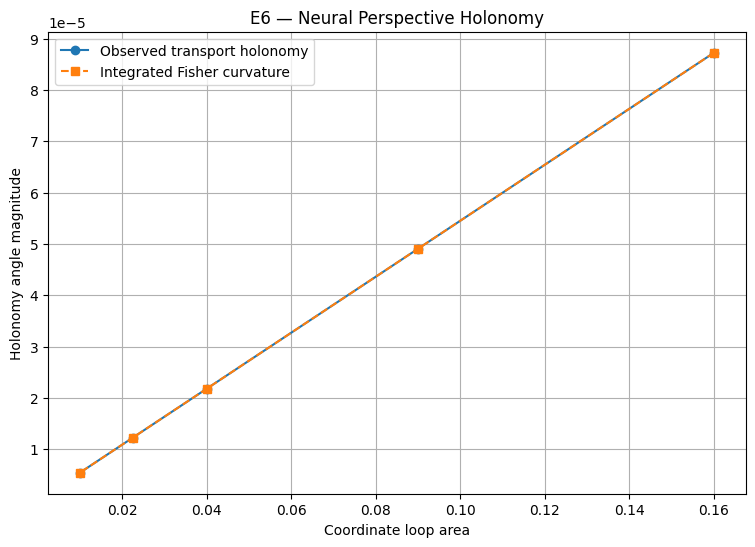

In [ ]:
plt.figure(
    figsize=(9, 6)
)

plt.plot(
    loop_df["coordinate_area"],
    np.abs(
        loop_df["observed"]
    ),
    "o-",
    label="Observed transport holonomy"
)

plt.plot(
    loop_df["coordinate_area"],
    np.abs(
        loop_df["predicted"]
    ),
    "s--",
    label="Integrated Fisher curvature"
)

plt.xlabel(
    "Coordinate loop area"
)

plt.ylabel(
    "Holonomy angle magnitude"
)

plt.title(
    "E6 — Neural Perspective Holonomy"
)

plt.legend()

plt.grid(True)

plt.show()